In [1]:
import jax
import jax.numpy as jnp 
import model 
import algos 
import matplotlib.pyplot as plt 


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


[[157.80205 604.58234 139.85867]
 [172.63257 524.8972  211.84694]
 [155.4419  622.4901  205.19398]
 ...
 [222.53516 423.78812 221.10347]
 [182.19713 400.73785 217.5701 ]
 [216.15529 437.38016 213.82487]]


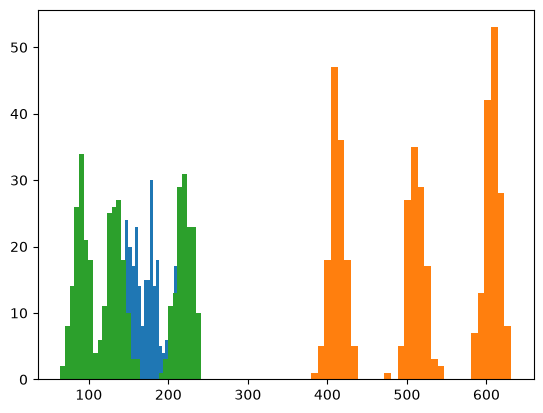

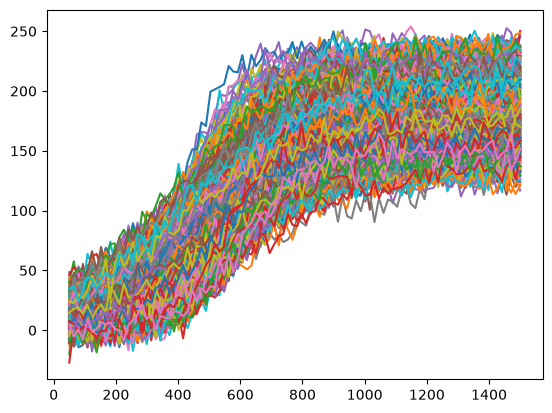

In [2]:
theta0 = model.parametrization.params_to_reals1d(
    asymptotic=200,
    inflexion=500,
    tau=150,
    cov_latent=jnp.diag(jnp.array([100, 100, 100])),
    var_residual=50,
)
z,y,t = model.simu_data(theta0, n =400, t = jnp.linspace(50, 1500, 100), prng_key=jax.random.PRNGKey(42))

print(z)
# plt.plot(t,y.T)
plt.hist(z[:, 0], bins=30)
plt.hist(z[:, 1], bins=30)
plt.hist(z[:, 2], bins=30)
plt.show()
plt.plot(t,y.T)

In [6]:
import jax
import jax.numpy as jnp

key1 = jax.random.PRNGKey(42)
n = 100

# Split keys
key_mean, key_comp, key_norm = jax.random.split(key1, 3)

base_mean = jnp.array([50, 100, 500])
L = jnp.linalg.cholesky(jnp.diag(jnp.array([100, 100, 100])))

# Define independent spreads for [asymptotic, inflexion, tau]
# Adjust these values so one parameter's variance doesn't overwhelm the others
spreads = jnp.array([10.0, 50.0, 5.0]) 

# Generate independent offsets for the 3 components across the 3 parameters
# jax.random.normal generates i.i.d (completely independent) values
gmm_means = base_mean + jax.random.normal(key_mean, shape=(3, 3)) * spreads

# Assign components independently
components = jax.random.randint(key_comp, shape=(n,3), minval=0, maxval=3)
assigned_means = gmm_means[components , jnp.arange(3)]  # Select the appropriate mean for each parameter

# Generate final samples
z = (jax.random.normal(key_norm, shape=(n, 3)) @ L.T) + assigned_means

In [7]:
print(assigned_means)

[[ 55.76161   59.626896 501.55176 ]
 [ 55.76161  115.02022  506.4516  ]
 [ 55.196117 115.02022  490.05838 ]
 [ 55.196117  59.626896 506.4516  ]
 [ 50.759254  75.68287  506.4516  ]
 [ 50.759254  75.68287  501.55176 ]
 [ 55.196117 115.02022  490.05838 ]
 [ 50.759254 115.02022  490.05838 ]
 [ 50.759254  59.626896 501.55176 ]
 [ 55.76161   59.626896 506.4516  ]
 [ 50.759254 115.02022  506.4516  ]
 [ 50.759254 115.02022  501.55176 ]
 [ 55.196117  75.68287  490.05838 ]
 [ 55.76161  115.02022  501.55176 ]
 [ 50.759254 115.02022  501.55176 ]
 [ 55.196117  75.68287  506.4516  ]
 [ 55.76161   59.626896 490.05838 ]
 [ 55.76161   75.68287  506.4516  ]
 [ 55.196117  59.626896 506.4516  ]
 [ 50.759254 115.02022  490.05838 ]
 [ 50.759254  59.626896 506.4516  ]
 [ 50.759254  75.68287  490.05838 ]
 [ 55.76161  115.02022  506.4516  ]
 [ 55.196117  75.68287  490.05838 ]
 [ 55.76161  115.02022  506.4516  ]
 [ 55.76161   75.68287  506.4516  ]
 [ 50.759254  75.68287  490.05838 ]
 [ 50.759254  75.68287  490.